In [14]:
!pip install kagglehub

In [15]:
import torch
from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

import seaborn as sns


In [16]:
import os

import kagglehub

# Download latest version
path = kagglehub.dataset_download("shubhambathwal/flight-price-prediction")

print("Path to dataset files:", path)
# Define the path to your dataset directory
# Replace 'your_dataset_path_here' with the actual path to your downloaded dataset

# List files in the downloaded directory
files = os.listdir(path)

# Assuming the CSV file is directly in the directory and is the only one or easily identifiable
csv_files = [f for f in files if f.endswith('.csv')]

# If there's at least one CSV file, take the first one (you might need to adjust if there are multiple CSVs)
if csv_files:
    csv_file_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(csv_file_path)
    df.head()
else:
    print("No CSV files found in the dataset directory.")

Using Colab cache for faster access to the 'flight-price-prediction' dataset.
Path to dataset files: /kaggle/input/flight-price-prediction


In [17]:
df.head(5)

,date,airline,ch_code,num_code,dep_time,from,time_taken,stop,arr_time,to,price
0,11-02-2022,Air India,AI,868,18:00,Delhi,02h 00m,non-stop,20:00,Mumbai,"25,612"
1,11-02-2022,Air India,AI,624,19:00,Delhi,02h 15m,non-stop,21:15,Mumbai,"25,612"
2,11-02-2022,Air India,AI,531,20:00,Delhi,24h 45m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,20:45,Mumbai,"42,220"
3,11-02-2022,Air India,AI,839,21:25,Delhi,26h 30m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,23:55,Mumbai,"44,450"
4,11-02-2022,Air India,AI,544,17:15,Delhi,06h 40m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,23:55,Mumbai,"46,690"


In [18]:
df.airline.value_counts()

,count
airline,
Vistara,60589
Air India,32898


In [19]:
df['from'].value_counts()

,count
from,
Mumbai,19858
Delhi,18316
Bangalore,16441
Kolkata,13473
Hyderabad,12870
Chennai,12529


In [20]:
df['stop'].value_counts()

,count
stop,
1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t\t\t\t\t\t\t,81489
non-stop,8102
2+-stop,1083
1-stop\n\t\t\t\t\t\t\t\t\t\t\t\tVia IDR\n\t\t\t\t\t\t\t\t\t\t\t\t,810
1-stop\n\t\t\t\t\t\t\t\t\t\t\t\tVia IXU\n\t\t\t\t\t\t\t\t\t\t\t\t,776
1-stop\n\t\t\t\t\t\t\t\t\t\t\t\tVia PAT\n\t\t\t\t\t\t\t\t\t\t\t\t,257
1-stop\n\t\t\t\t\t\t\t\t\t\t\t\tVia Patna\n\t\t\t\t\t\t\t\t\t\t\t\t,242
1-stop\n\t\t\t\t\t\t\t\t\t\t\t\tVia BBI\n\t\t\t\t\t\t\t\t\t\t\t\t,152
1-stop\n\t\t\t\t\t\t\t\t\t\t\t\tVia STV\n\t\t\t\t\t\t\t\t\t\t\t\t,93


In [21]:

df = df.drop(columns=['num_code'])


In [22]:
df['day'] = pd.to_datetime(df['date'], format='%d-%m-%Y').dt.day
df['month'] = pd.to_datetime(df['date'], format='%d-%m-%Y').dt.month

In [23]:
# Extract hours and minutes from 'time_taken' column
df['hr_time'] = df['time_taken'].apply(lambda x: int(x.split('h')[0]))
df['min_time'] = df['time_taken'].apply(lambda x: int(x.split('h')[1].replace('m', '').strip()))

In [24]:
df.head(20)

,date,airline,ch_code,dep_time,from,time_taken,stop,arr_time,to,price,day,month,hr_time,min_time
0,11-02-2022,Air India,AI,18:00,Delhi,02h 00m,non-stop,20:00,Mumbai,"25,612",11,2,2,0
1,11-02-2022,Air India,AI,19:00,Delhi,02h 15m,non-stop,21:15,Mumbai,"25,612",11,2,2,15
2,11-02-2022,Air India,AI,20:00,Delhi,24h 45m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,20:45,Mumbai,"42,220",11,2,24,45
3,11-02-2022,Air India,AI,21:25,Delhi,26h 30m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,23:55,Mumbai,"44,450",11,2,26,30
4,11-02-2022,Air India,AI,17:15,Delhi,06h 40m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,23:55,Mumbai,"46,690",11,2,6,40
5,11-02-2022,Vistara,UK,19:50,Delhi,02h 10m,non-stop,22:00,Mumbai,"50,264",11,2,2,10
6,11-02-2022,Air India,AI,21:15,Delhi,17h 45m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,15:00,Mumbai,"50,669",11,2,17,45
7,11-02-2022,Air India,AI,18:40,Delhi,22h 45m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,17:25,Mumbai,"51,059",11,2,22,45
8,11-02-2022,Vistara,UK,20:35,Delhi,17h 55m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,14:30,Mumbai,"51,731",11,2,17,55
9,11-02-2022,Vistara,UK,19:00,Delhi,02h 15m,non-stop,21:15,Mumbai,"53,288",11,2,2,15


In [25]:
df.drop(columns=('date'))

,airline,ch_code,dep_time,from,time_taken,stop,arr_time,to,price,day,month,hr_time,min_time
0,Air India,AI,18:00,Delhi,02h 00m,non-stop,20:00,Mumbai,"25,612",11,2,2,0
1,Air India,AI,19:00,Delhi,02h 15m,non-stop,21:15,Mumbai,"25,612",11,2,2,15
2,Air India,AI,20:00,Delhi,24h 45m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,20:45,Mumbai,"42,220",11,2,24,45
3,Air India,AI,21:25,Delhi,26h 30m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,23:55,Mumbai,"44,450",11,2,26,30
4,Air India,AI,17:15,Delhi,06h 40m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,23:55,Mumbai,"46,690",11,2,6,40
...,...,...,...,...,...,...,...,...,...,...,...,...,...
93482,Vistara,UK,09:45,Chennai,10h 05m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,19:50,Hyderabad,"69,265",31,3,10,5
93483,Vistara,UK,12:30,Chennai,10h 25m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,22:55,Hyderabad,"77,105",31,3,10,25
93484,Vistara,UK,07:05,Chennai,13h 50m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,20:55,Hyderabad,"79,099",31,3,13,50
93485,Vistara,UK,07:00,Chennai,10h 00m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,17:00,Hyderabad,"81,585",31,3,10,0


In [26]:
df.head(5)

,date,airline,ch_code,dep_time,from,time_taken,stop,arr_time,to,price,day,month,hr_time,min_time
0,11-02-2022,Air India,AI,18:00,Delhi,02h 00m,non-stop,20:00,Mumbai,"25,612",11,2,2,0
1,11-02-2022,Air India,AI,19:00,Delhi,02h 15m,non-stop,21:15,Mumbai,"25,612",11,2,2,15
2,11-02-2022,Air India,AI,20:00,Delhi,24h 45m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,20:45,Mumbai,"42,220",11,2,24,45
3,11-02-2022,Air India,AI,21:25,Delhi,26h 30m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,23:55,Mumbai,"44,450",11,2,26,30
4,11-02-2022,Air India,AI,17:15,Delhi,06h 40m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,23:55,Mumbai,"46,690",11,2,6,40


In [27]:
df.drop(columns=['time_taken'], inplace=True)

In [28]:
df.drop(columns=['date'], inplace=True)

In [29]:
df.head(7)

,airline,ch_code,dep_time,from,stop,arr_time,to,price,day,month,hr_time,min_time
0,Air India,AI,18:00,Delhi,non-stop,20:00,Mumbai,"25,612",11,2,2,0
1,Air India,AI,19:00,Delhi,non-stop,21:15,Mumbai,"25,612",11,2,2,15
2,Air India,AI,20:00,Delhi,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,20:45,Mumbai,"42,220",11,2,24,45
3,Air India,AI,21:25,Delhi,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,23:55,Mumbai,"44,450",11,2,26,30
4,Air India,AI,17:15,Delhi,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,23:55,Mumbai,"46,690",11,2,6,40
5,Vistara,UK,19:50,Delhi,non-stop,22:00,Mumbai,"50,264",11,2,2,10
6,Air India,AI,21:15,Delhi,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,15:00,Mumbai,"50,669",11,2,17,45


In [30]:
df['arr_hr'] = pd.to_datetime(df['arr_time'], format='%H:%M').dt.hour
df['arr_min'] = pd.to_datetime(df['arr_time'], format='%H:%M').dt.minute
df['dep_hr'] = pd.to_datetime(df['dep_time'], format='%H:%M').dt.hour
df['dep_min'] = pd.to_datetime(df['dep_time'], format='%H:%M').dt.minute

In [31]:
df.drop(columns=['arr_time'], inplace=True)
df.drop(columns=['dep_time'], inplace=True)

In [32]:
df.head(10)

,airline,ch_code,from,stop,to,price,day,month,hr_time,min_time,arr_hr,arr_min,dep_hr,dep_min
0,Air India,AI,Delhi,non-stop,Mumbai,"25,612",11,2,2,0,20,0,18,0
1,Air India,AI,Delhi,non-stop,Mumbai,"25,612",11,2,2,15,21,15,19,0
2,Air India,AI,Delhi,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,Mumbai,"42,220",11,2,24,45,20,45,20,0
3,Air India,AI,Delhi,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,Mumbai,"44,450",11,2,26,30,23,55,21,25
4,Air India,AI,Delhi,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,Mumbai,"46,690",11,2,6,40,23,55,17,15
5,Vistara,UK,Delhi,non-stop,Mumbai,"50,264",11,2,2,10,22,0,19,50
6,Air India,AI,Delhi,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,Mumbai,"50,669",11,2,17,45,15,0,21,15
7,Air India,AI,Delhi,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,Mumbai,"51,059",11,2,22,45,17,25,18,40
8,Vistara,UK,Delhi,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,Mumbai,"51,731",11,2,17,55,14,30,20,35
9,Vistara,UK,Delhi,non-stop,Mumbai,"53,288",11,2,2,15,21,15,19,0


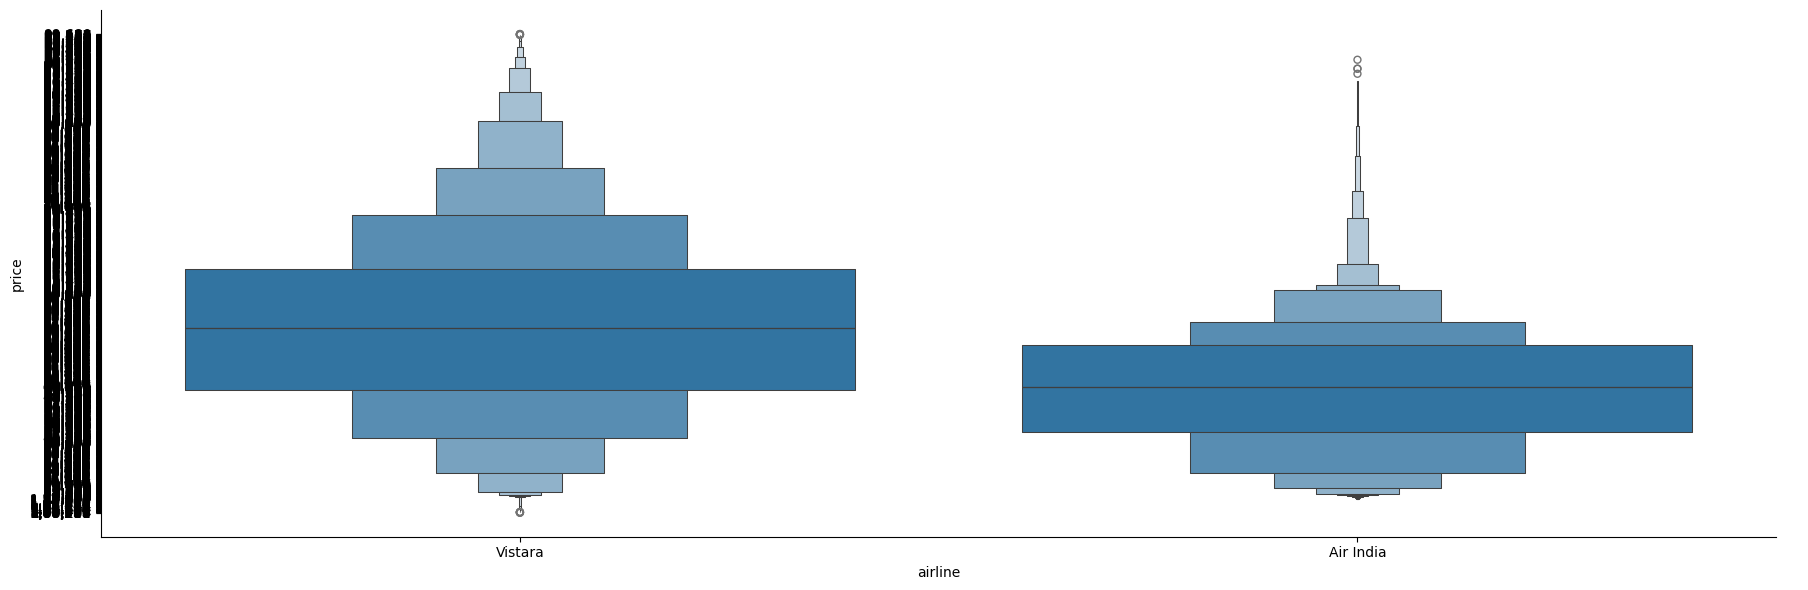

In [33]:
sns.catplot(y = "price", x = "airline", data = df.sort_values("price", ascending = False), kind="boxen", height = 6, aspect = 3)
plt.show()

In [34]:
airline = df[["airline"]]
airline = pd.get_dummies(airline, dtype=int)
airline.head(11)

,airline_Air India,airline_Vistara
0,1,0
1,1,0
2,1,0
3,1,0
4,1,0
5,0,1
6,1,0
7,1,0
8,0,1
9,0,1


In [35]:
source = df[["from"]]
source = pd.get_dummies(source, dtype=int)
source.tail(11)

,from_Bangalore,from_Chennai,from_Delhi,from_Hyderabad,from_Kolkata,from_Mumbai
93476,0,1,0,0,0,0
93477,0,1,0,0,0,0
93478,0,1,0,0,0,0
93479,0,1,0,0,0,0
93480,0,1,0,0,0,0
93481,0,1,0,0,0,0
93482,0,1,0,0,0,0
93483,0,1,0,0,0,0
93484,0,1,0,0,0,0
93485,0,1,0,0,0,0


In [36]:
destination = df[["to"]]
destination = pd.get_dummies(destination, dtype=int)
destination.tail(11)

,to_Bangalore,to_Chennai,to_Delhi,to_Hyderabad,to_Kolkata,to_Mumbai
93476,0,0,0,1,0,0
93477,0,0,0,1,0,0
93478,0,0,0,1,0,0
93479,0,0,0,1,0,0
93480,0,0,0,1,0,0
93481,0,0,0,1,0,0
93482,0,0,0,1,0,0
93483,0,0,0,1,0,0
93484,0,0,0,1,0,0
93485,0,0,0,1,0,0


In [37]:
df.drop(columns=['ch_code'], inplace=True)
df.head()

,airline,from,stop,to,price,day,month,hr_time,min_time,arr_hr,arr_min,dep_hr,dep_min
0,Air India,Delhi,non-stop,Mumbai,"25,612",11,2,2,0,20,0,18,0
1,Air India,Delhi,non-stop,Mumbai,"25,612",11,2,2,15,21,15,19,0
2,Air India,Delhi,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,Mumbai,"42,220",11,2,24,45,20,45,20,0
3,Air India,Delhi,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,Mumbai,"44,450",11,2,26,30,23,55,21,25
4,Air India,Delhi,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,Mumbai,"46,690",11,2,6,40,23,55,17,15


In [38]:
df['stop'].replace('non-stop', 0, inplace=True)
df['stop'].replace('1-stop', 1, inplace=True)
df['stop'].replace('2-stop', 2, inplace=True)
df['stop'].replace('3-stop', 3, inplace=True)

/tmp/ipykernel_1055/3292933436.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['stop'].replace('non-stop', 0, inplace=True)
/tmp/ipykernel_1055/3292933436.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try u

In [39]:
df.head(10)

,airline,from,stop,to,price,day,month,hr_time,min_time,arr_hr,arr_min,dep_hr,dep_min
0,Air India,Delhi,non-stop,Mumbai,"25,612",11,2,2,0,20,0,18,0
1,Air India,Delhi,non-stop,Mumbai,"25,612",11,2,2,15,21,15,19,0
2,Air India,Delhi,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,Mumbai,"42,220",11,2,24,45,20,45,20,0
3,Air India,Delhi,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,Mumbai,"44,450",11,2,26,30,23,55,21,25
4,Air India,Delhi,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,Mumbai,"46,690",11,2,6,40,23,55,17,15
5,Vistara,Delhi,non-stop,Mumbai,"50,264",11,2,2,10,22,0,19,50
6,Air India,Delhi,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,Mumbai,"50,669",11,2,17,45,15,0,21,15
7,Air India,Delhi,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,Mumbai,"51,059",11,2,22,45,17,25,18,40
8,Vistara,Delhi,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,Mumbai,"51,731",11,2,17,55,14,30,20,35
9,Vistara,Delhi,non-stop,Mumbai,"53,288",11,2,2,15,21,15,19,0


In [40]:
import re

def get_stop_count(x):
  if 'non-stop' in x:
    return 0
  elif '2+-stop' in x:
    return 2
  elif '1-stop' in x:
    return 1
  return None


df['stop_count'] = df['stop'].apply(get_stop_count)

df = df.drop(columns=['stop'])

df.head(10)

,airline,from,to,price,day,month,hr_time,min_time,arr_hr,arr_min,dep_hr,dep_min,stop_count
0,Air India,Delhi,Mumbai,"25,612",11,2,2,0,20,0,18,0,0
1,Air India,Delhi,Mumbai,"25,612",11,2,2,15,21,15,19,0,0
2,Air India,Delhi,Mumbai,"42,220",11,2,24,45,20,45,20,0,1
3,Air India,Delhi,Mumbai,"44,450",11,2,26,30,23,55,21,25,1
4,Air India,Delhi,Mumbai,"46,690",11,2,6,40,23,55,17,15,1
5,Vistara,Delhi,Mumbai,"50,264",11,2,2,10,22,0,19,50,0
6,Air India,Delhi,Mumbai,"50,669",11,2,17,45,15,0,21,15,1
7,Air India,Delhi,Mumbai,"51,059",11,2,22,45,17,25,18,40,1
8,Vistara,Delhi,Mumbai,"51,731",11,2,17,55,14,30,20,35,1
9,Vistara,Delhi,Mumbai,"53,288",11,2,2,15,21,15,19,0,0


In [41]:
df['stop_count'].value_counts()

,count
stop_count,
1,84302
0,8102
2,1083


In [43]:
df = pd.concat([df, airline, source, destination], axis =1)
# Display data types after concatenation to ensure all columns are appropriate for model training.
print("Data types after concatenating features:")
print(df.dtypes)

In [45]:
df.drop(["airline", "from", "to"], axis = 1, inplace=True)

In [46]:
df.head(10)

,price,day,month,hr_time,min_time,arr_hr,arr_min,dep_hr,dep_min,stop_count,...,from_Delhi,from_Hyderabad,from_Kolkata,from_Mumbai,to_Bangalore,to_Chennai,to_Delhi,to_Hyderabad,to_Kolkata,to_Mumbai
0,"25,612",11,2,2,0,20,0,18,0,0,...,1,0,0,0,0,0,0,0,0,1
1,"25,612",11,2,2,15,21,15,19,0,0,...,1,0,0,0,0,0,0,0,0,1
2,"42,220",11,2,24,45,20,45,20,0,1,...,1,0,0,0,0,0,0,0,0,1
3,"44,450",11,2,26,30,23,55,21,25,1,...,1,0,0,0,0,0,0,0,0,1
4,"46,690",11,2,6,40,23,55,17,15,1,...,1,0,0,0,0,0,0,0,0,1
5,"50,264",11,2,2,10,22,0,19,50,0,...,1,0,0,0,0,0,0,0,0,1
6,"50,669",11,2,17,45,15,0,21,15,1,...,1,0,0,0,0,0,0,0,0,1
7,"51,059",11,2,22,45,17,25,18,40,1,...,1,0,0,0,0,0,0,0,0,1
8,"51,731",11,2,17,55,14,30,20,35,1,...,1,0,0,0,0,0,0,0,0,1
9,"53,288",11,2,2,15,21,15,19,0,0,...,1,0,0,0,0,0,0,0,0,1


In [47]:
X = df.drop(columns=['price'])
y = df['price']

In [48]:
split_idx = int(len(df) * 0.8)

X_train = X.iloc[:split_idx]
y_train = y.iloc[:split_idx]

X_test = X.iloc[split_idx:]
y_test = y.iloc[split_idx:]

print(X_train.shape, X_test.shape)

(74789, 23) (18698, 23)


In [49]:
X_train.columns

Index(['day', 'month', 'hr_time', 'min_time', 'arr_hr', 'arr_min', 'dep_hr',
       'dep_min', 'stop_count', 'airline_Air India', 'airline_Vistara',
       'from_Bangalore', 'from_Chennai', 'from_Delhi', 'from_Hyderabad',
       'from_Kolkata', 'from_Mumbai', 'to_Bangalore', 'to_Chennai', 'to_Delhi',
       'to_Hyderabad', 'to_Kolkata', 'to_Mumbai'],
      dtype='object')

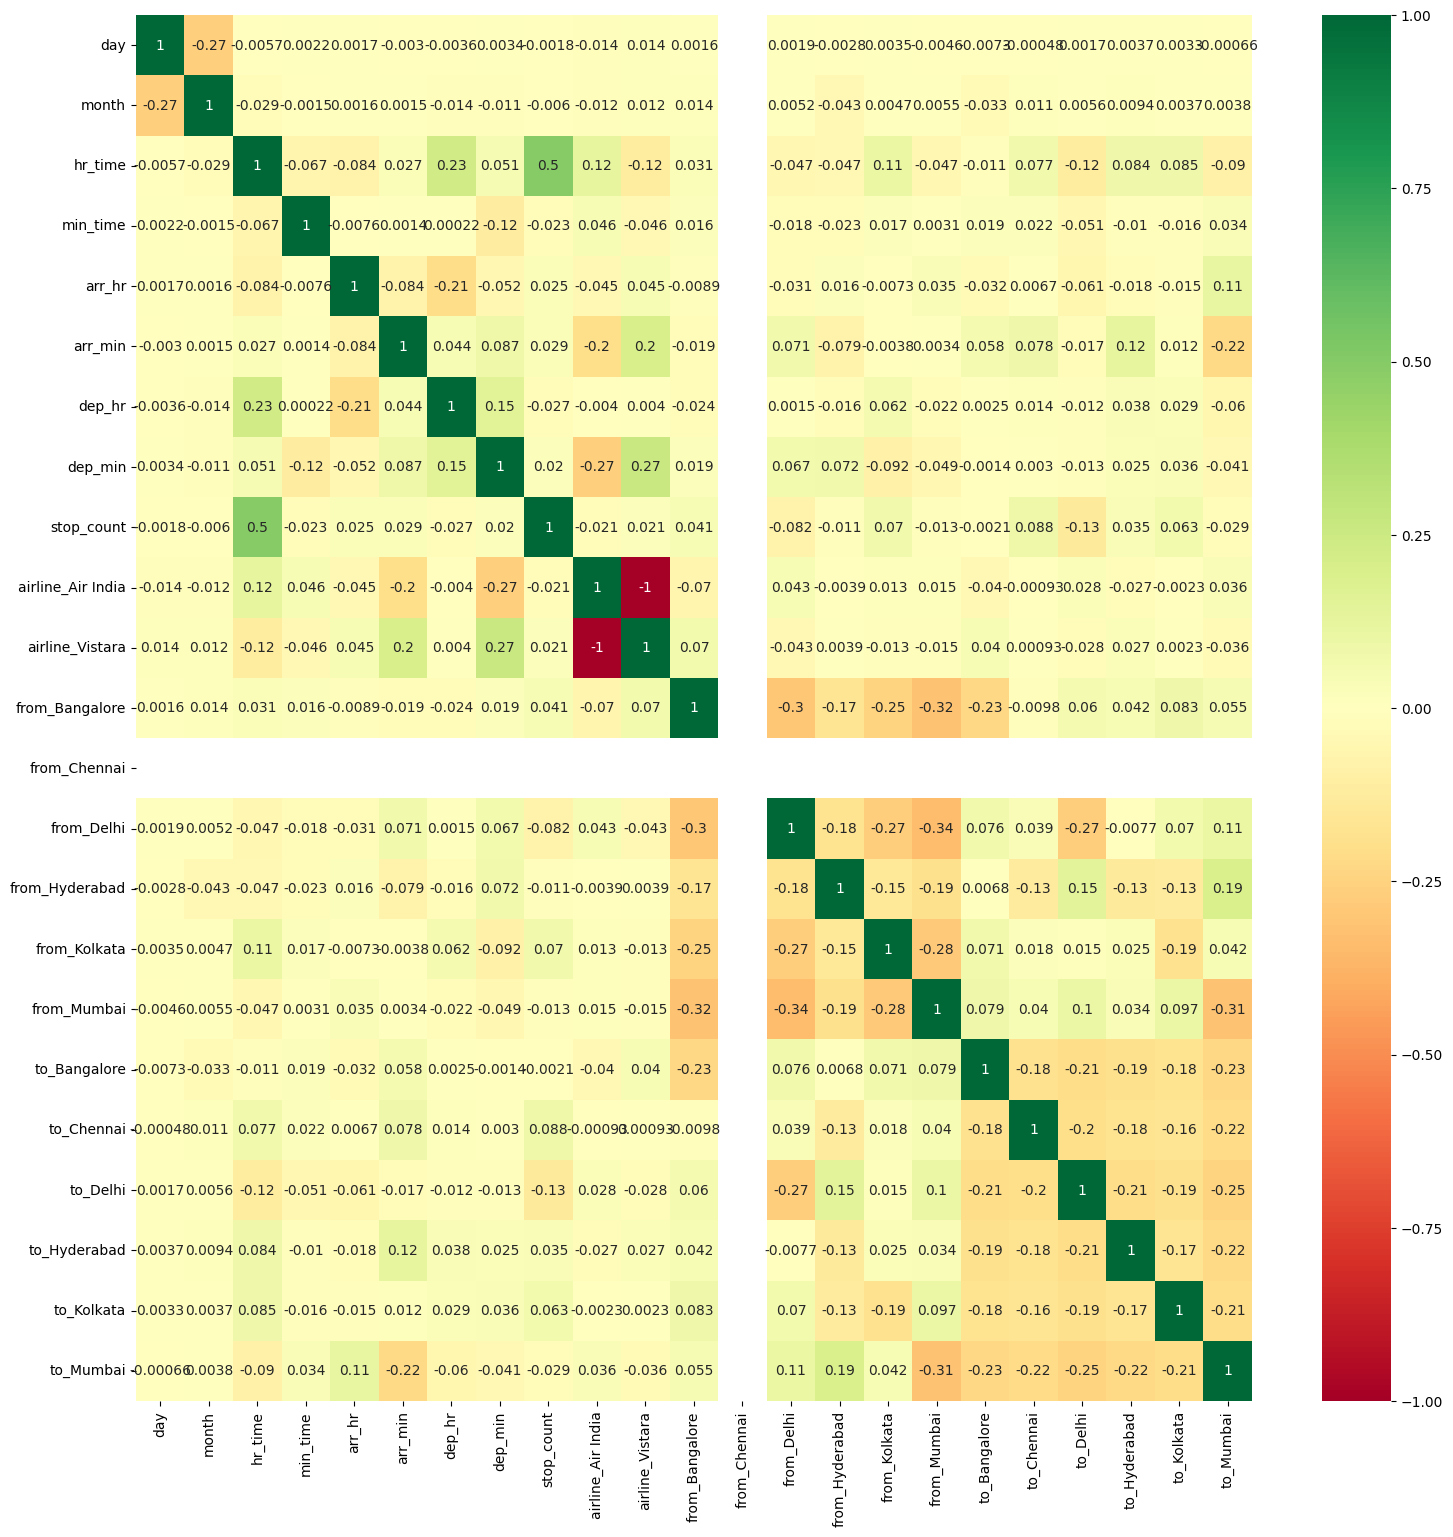

In [50]:
plt.figure(figsize= (18,18))
sns.heatmap(X_train.corr(), annot = True, cmap = "RdYlGn")

plt.show()

In [52]:
df['price'] = df['price'].astype(str).str.replace(',', '').astype(float)

In [54]:
from sklearn.ensemble import ExtraTreesRegressor

# Re-assign X and y to ensure 'price' column in y is numerical
X = df.drop(columns=['price'])
y = df['price']

selection = ExtraTreesRegressor()
selection.fit(X, y)

ExtraTreesRegressor()

In [55]:
print(selection.feature_importances_)

[0.07890465 0.01093179 0.09368143 0.02277043 0.05596454 0.04774817
 0.0480037  0.04345315 0.30325806 0.04222463 0.05023851 0.0093497
 0.0069585  0.03982523 0.01255283 0.01482321 0.02003032 0.01147008
 0.00723575 0.03732616 0.01094771 0.016792   0.01550944]


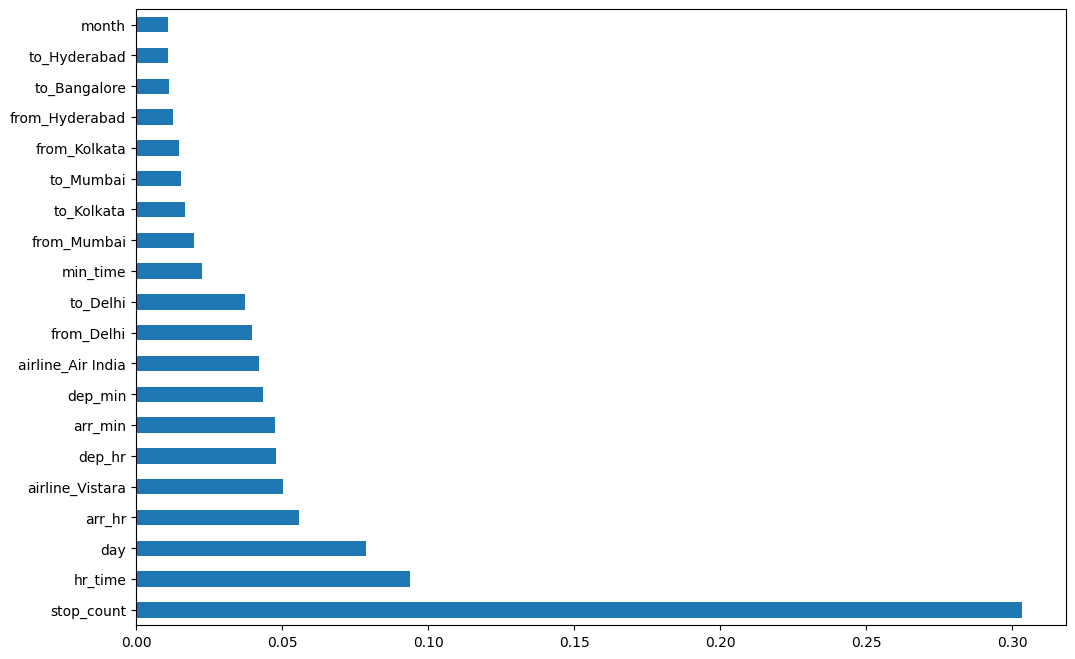

In [56]:
plt.figure(figsize = (12,8))
feat_importances = pd.Series(selection.feature_importances_, index=X.columns)
feat_importances.nlargest(20).plot(kind='barh')
plt.show()


In [57]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [58]:
from sklearn.ensemble import RandomForestRegressor
reg_rf = RandomForestRegressor()
reg_rf.fit(X_train, y_train)


RandomForestRegressor()

In [63]:
y_pred = reg_rf.predict(X_test)

In [64]:
reg_rf.score(X_train, y_train)

0.9874502220938661

In [65]:
reg_rf.score(X_test, y_test)

0.9204965380600718

/tmp/ipykernel_1055/2619859745.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(y_test-y_pred)


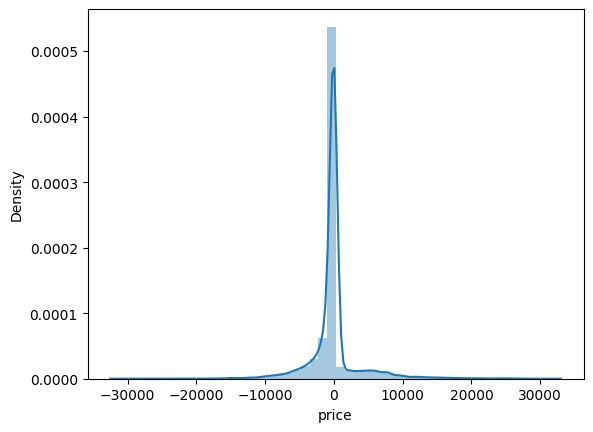

In [66]:
sns.distplot(y_test-y_pred)
plt.show()


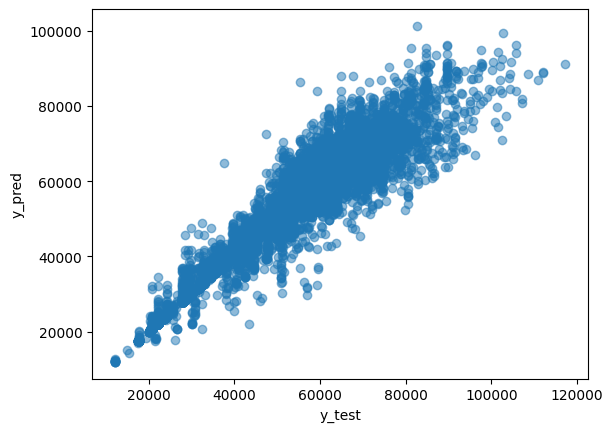

In [67]:
plt.scatter(y_test, y_pred, alpha = 0.5)
plt.xlabel("y_test")
plt.ylabel("y_pred")
plt.show()

In [68]:
from sklearn import metrics

print('MAE:', metrics.mean_absolute_error(y_test, y_pred))
print('MSE:', metrics.mean_squared_error(y_test, y_pred))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, y_pred)))



MAE: 1667.190814019452
MSE: 13445108.64708496
RMSE: 3666.7572386353804


In [70]:
2090.5509/(max(y)-min(y))

0.018821752752743743

In [71]:
metrics.r2_score(y_test, y_pred)

0.9204965380600718

In [75]:
import pickle

with open('flight_rf.pkl', 'wb') as file:
    pickle.dump(reg_rf, file)

with open('flight_rf.pkl','rb') as model_file:
    forest = pickle.load(model_file)

y_prediction = forest.predict(X_test)

metrics.r2_score(y_test, y_prediction)

0.9204965380600718